In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv('WA_Marketing-Campaign.csv')

In [2]:
df.head(20)

,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
0,1,Medium,1,4,3,1,33.73
1,1,Medium,1,4,3,2,35.67
2,1,Medium,1,4,3,3,29.03
3,1,Medium,1,4,3,4,39.25
4,1,Medium,2,5,2,1,27.81
5,1,Medium,2,5,2,2,34.67
6,1,Medium,2,5,2,3,27.98
7,1,Medium,2,5,2,4,27.72
8,1,Medium,3,12,1,1,44.54
9,1,Medium,3,12,1,2,37.94


# Fast Food Marketing Campaign A/B Test

## Data Check and Initial EDA

The goal of this project is to compare three promotion strategies and see whether they lead to different sales performance.

Before testing the promotion effect, I first checked the dataset for missing values, duplicates, and how the three promotion groups were distributed across markets and stores.


In [59]:
df.describe()

,MarketID,LocationID,AgeOfStore,Promotion,week,SalesInThousands
count,548.000000,548.000000,548.000000,548.000000,548.000000,548.000000
mean,5.715328,479.656934,8.503650,2.029197,2.500000,53.466204
std,2.877001,287.973679,6.638345,0.810729,1.119055,16.755216
min,1.000000,1.000000,1.000000,1.000000,1.000000,17.340000
25%,3.000000,216.000000,4.000000,1.000000,1.750000,42.545000
50%,6.000000,504.000000,7.000000,2.000000,2.500000,50.200000
75%,8.000000,708.000000,12.000000,3.000000,3.250000,60.477500
max,10.000000,920.000000,28.000000,3.000000,4.000000,99.650000


In [10]:
# understand each columns
for col in df.columns:
    counts = df[col].nunique()
    print(f'number of nuique columns in {col} is {counts}')

number of nuique columns in MarketID is 10
number of nuique columns in MarketSize is 3
number of nuique columns in LocationID is 137
number of nuique columns in AgeOfStore is 25
number of nuique columns in Promotion is 3
number of nuique columns in week is 4
number of nuique columns in SalesInThousands is 517


In [11]:
# understand each columns
for col in df.columns:
    counts = df[col].isna().sum()
    print(f'number of nuique columns in {col} is {counts}')
# no missing value in the dataset

number of nuique columns in MarketID is 0
number of nuique columns in MarketSize is 0
number of nuique columns in LocationID is 0
number of nuique columns in AgeOfStore is 0
number of nuique columns in Promotion is 0
number of nuique columns in week is 0
number of nuique columns in SalesInThousands is 0


In [13]:
# understand each columns
df.duplicated().sum()
# no duplicated value in the dataset

0

In [15]:
df.head(5)

,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
0,1,Medium,1,4,3,1,33.73
1,1,Medium,1,4,3,2,35.67
2,1,Medium,1,4,3,3,29.03
3,1,Medium,1,4,3,4,39.25
4,1,Medium,2,5,2,1,27.81


In [26]:
marketid_summary = df.groupby(['MarketID','Promotion']).agg(totalsalesInThousands = ('SalesInThousands','sum'),
                           avgsalesInThousands = ('SalesInThousands','mean') ,
                            salesInThousandscount = ('SalesInThousands','count')).reset_index()

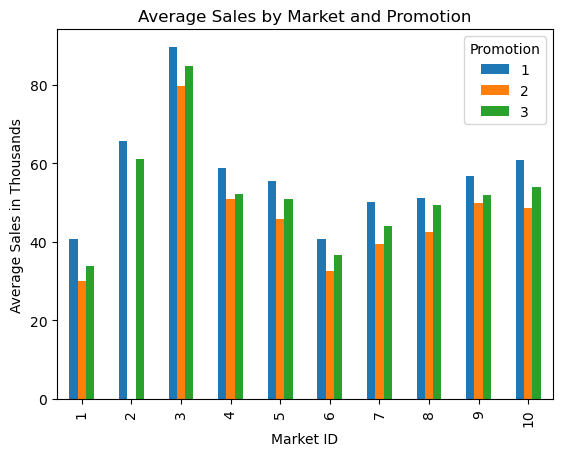

In [27]:
import matplotlib.pyplot as plt

marketid_summary.pivot(
    index='MarketID',
    columns='Promotion',
    values='avgsalesInThousands'
).plot(kind='bar')

plt.xlabel('Market ID')
plt.ylabel('Average Sales in Thousands')
plt.title('Average Sales by Market and Promotion')
plt.legend(title='Promotion')
plt.show()

From the first market-level comparison, I noticed that Promotion 2 does not appear in MarketID 2. Because of that, I wanted to look at how the promotions were assigned across markets before comparing sales.

The other markets contain all three promotion groups, but I do not want to assume the groups are balanced just from the chart, so I check the group distributions next.


In [31]:
marketsize_summary = df.groupby(['MarketSize','Promotion']).agg(totalsalesInThousands = ('SalesInThousands','sum'),
                           avgsalesInThousands = ('SalesInThousands','mean') ,
                            salesInThousandscount = ('SalesInThousands','count')).reset_index()


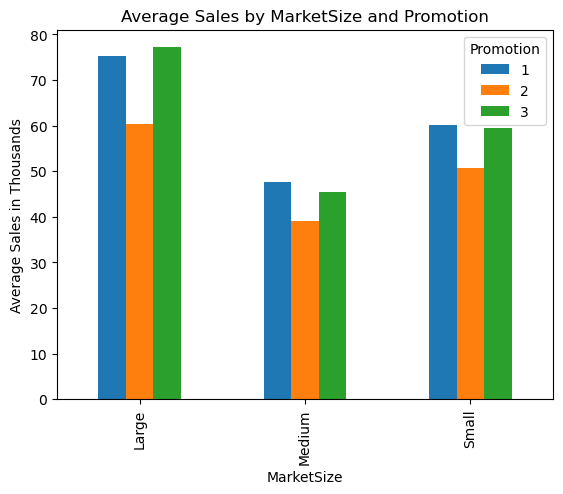

In [33]:
import matplotlib.pyplot as plt

marketsize_summary.pivot(
    index='MarketSize',
    columns='Promotion',
    values='avgsalesInThousands'
).plot(kind='bar')

plt.xlabel('MarketSize')
plt.ylabel('Average Sales in Thousands')
plt.title('Average Sales by MarketSize and Promotion')
plt.legend(title='Promotion')
plt.show()

Looking across market sizes, all three promotions are represented in Large, Medium, and Small markets.

Promotion 2 also appears to have lower average sales than Promotions 1 and 3 across the different market sizes. This is an early pattern, but I would not make a conclusion from the averages alone. I still need to check whether the promotion groups have similar market-size distributions.


In [44]:
pd.crosstab(
    df['MarketSize'],
    df['Promotion'],
    normalize='index'
)

Promotion,1,2,3
MarketSize,,,
Large,0.333333,0.380952,0.285714
Medium,0.300000,0.337500,0.362500
Small,0.333333,0.266667,0.400000


In [39]:
df.groupby('Promotion')['AgeOfStore'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
Promotion,,,,
1,172,8.279070,6.0,6.636160
2,188,7.978723,7.0,6.597648
3,188,9.234043,8.0,6.651646


In [55]:
age_summary = df.groupby('Promotion')['AgeOfStore'].count().reset_index()
age_summary

,Promotion,AgeOfStore
0,1,172
1,2,188
2,3,188


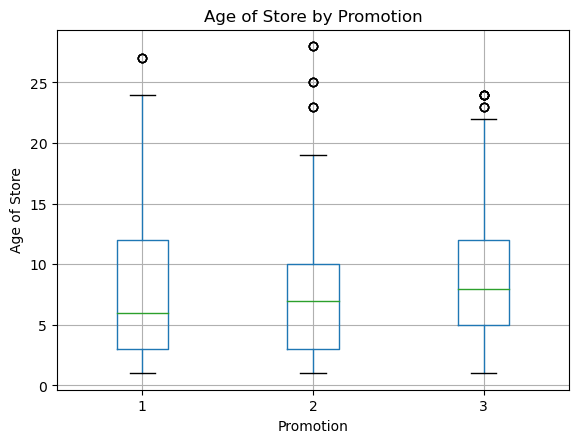

In [57]:
import matplotlib.pyplot as plt

df.boxplot(
    column='AgeOfStore',
    by='Promotion'
)

plt.title('Age of Store by Promotion')
plt.suptitle('')
plt.xlabel('Promotion')
plt.ylabel('Age of Store')
plt.show()

In [58]:
from scipy.stats import f_oneway

age1 = df[df['Promotion'] == 1]['AgeOfStore']
age2 = df[df['Promotion'] == 2]['AgeOfStore']
age3 = df[df['Promotion'] == 3]['AgeOfStore']

f_stat, p_value = f_oneway(age1, age2, age3)

print('F-statistic:', f_stat)
print('p-value:', p_value)

F-statistic: 1.8296733887825316
p-value: 0.1614502603161125


Using a 0.05 significance level, the ANOVA does not show a significant difference in average store age across the three promotion groups.

This means I do not find evidence that one promotion group contains systematically older or newer stores than the others. Store age therefore looks reasonably balanced across groups.


In [40]:
pd.crosstab(df['LocationID'], df['Promotion'])

Promotion,1,2,3
LocationID,,,
1,0,0,4
2,0,4,0
3,4,0,0
4,0,4,0
5,0,4,0
...,...,...,...
916,0,4,0
917,0,0,4
918,4,0,0


In [42]:
pd.crosstab(df['MarketID'], df['Promotion'],normalize='index')

Promotion,1,2,3
MarketID,,,
1,0.384615,0.384615,0.230769
2,0.166667,0.000000,0.833333
3,0.318182,0.272727,0.409091
4,0.444444,0.444444,0.111111
5,0.133333,0.533333,0.333333
6,0.333333,0.400000,0.266667
7,0.266667,0.266667,0.466667
8,0.416667,0.166667,0.416667
9,0.300000,0.200000,0.500000


The promotion groups are not exactly identical, which is normal in a randomized experiment. From the initial checks, the sample sizes, market-size mix, and store ages look reasonably similar.

I also check the promotion counts at the store level and run a formal balance test for MarketSize before moving to the sales comparison.


In [60]:
### Chi-square goodness of fit test for check no SMR
store_df = df.drop_duplicates(subset='LocationID').copy() # check by each week

store_df.shape

(137, 7)

In [62]:
store_df['Promotion'].value_counts().sort_index()

1    43
2    47
3    47
Name: Promotion, dtype: int64

In [63]:
from scipy.stats import chisquare
import numpy as np

observed = (
    store_df['Promotion']
    .value_counts()
    .sort_index()
    .values
)

expected = np.repeat(len(store_df) / 3, 3)

chi2, p_value = chisquare(
    f_obs=observed,
    f_exp=expected
)

print("Observed:", observed)
print("Expected:", expected)
print("Chi-square:", chi2)
print("p-value:", p_value)

Observed: [43 47 47]
Expected: [45.66666667 45.66666667 45.66666667]
Chi-square: 0.23357664233576644
p-value: 0.8897735194498095


In [65]:
#  Check categorical baseline variables — Chi-square test of independence
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(
    pd.crosstab(store_df['MarketSize'],store_df['Promotion'])
)

print("Chi-square:", chi2)
print("p-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square: 1.1884728210928113
p-value: 0.8799928219560625
Degrees of freedom: 4


The MarketSize balance test is not statistically significant at the 0.05 level.

So I do not find evidence that the proportions of Large, Medium, and Small markets are different across the three promotion groups. This gives me more confidence that market size is not driving the promotion comparison.


# Promotion Effect on Sales


### Hypotheses

**Null hypothesis:** The average sales are the same across Promotions 1, 2, and 3.

**Alternative hypothesis:** At least one promotion has a different average sales level.


In [68]:
from scipy.stats import f_oneway

promo1 = df.loc[df['Promotion'] == 1, 'SalesInThousands']
promo2 = df.loc[df['Promotion'] == 2, 'SalesInThousands']
promo3 = df.loc[df['Promotion'] == 3, 'SalesInThousands']

f_stat, p_value = f_oneway(
    promo1,
    promo2,
    promo3
)

print("F-statistic:", f_stat)
print("p-value:", p_value)


F-statistic: 21.953485793080677
p-value: 6.765849261408714e-10


The ANOVA p-value is below 0.05, so I reject the null hypothesis.

This tells me that sales are not the same across all three promotion groups, but ANOVA does not tell me which promotions are different. I use Tukey HSD next for the pairwise comparisons.


### Tukey HSD Pairwise Comparison

Since the overall ANOVA is significant, I use Tukey HSD to compare the promotion groups pair by pair while controlling for multiple comparisons.


In [69]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tukey = pairwise_tukeyhsd(endog=df['SalesInThousands'], groups=df['Promotion'], alpha=0.05)


In [70]:
print(tukey)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     1      2 -10.7696    0.0 -14.7738 -6.7654   True
     1      3  -2.7345 0.2444  -6.7388  1.2697  False
     2      3   8.0351    0.0   4.1208 11.9493   True
-----------------------------------------------------


In [73]:
df.groupby('Promotion')['SalesInThousands'].mean().sort_values(ascending=False)

Promotion
1    58.099012
3    55.364468
2    47.329415
Name: SalesInThousands, dtype: float64

In [74]:
mean_1 = df.loc[df['Promotion'] == 1, 'SalesInThousands'].mean()
mean_2 = df.loc[df['Promotion'] == 2, 'SalesInThousands'].mean()
mean_3 = df.loc[df['Promotion'] == 3, 'SalesInThousands'].mean()

print("Promotion 1 vs 2:", mean_1 - mean_2)
print("Promotion 1 vs 3:", mean_1 - mean_3)
print("Promotion 3 vs 2:", mean_3 - mean_2)

Promotion 1 vs 2: 10.769596734289962
Promotion 1 vs 3: 2.7345435428006795
Promotion 3 vs 2: 8.035053191489283


Promotion 1 and Promotion 3 both have higher average sales than Promotion 2.

The difference between Promotion 1 and Promotion 3 is not statistically significant, so even though Promotion 1 has the highest observed average, I do not have enough evidence to say it performs better than Promotion 3.

At this point, the main result is that Promotion 2 underperforms, while Promotions 1 and 3 perform similarly.


### Mixed-Effects Model: Accounting for Repeated Store Measurements

Each store appears multiple times because sales are recorded across four weeks. Those observations from the same store are related, so I also fit a mixed-effects model with `LocationID` as a random effect.

This lets me compare promotions while allowing each store to have its own baseline sales level.


\[
Sales_{it}=\beta_0
+\beta_1 Promotion2_i
+\beta_2 Promotion3_i
+u_i
+\epsilon_{it}
\]

Here, Promotion 1 is the reference group and \(u_i\) captures store-level differences.


In [75]:
import statsmodels.formula.api as smf

model = smf.mixedlm(
    "SalesInThousands ~ C(Promotion)",
    data=df,
    groups=df["LocationID"]
)

result = model.fit()

print(result.summary())

            Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: SalesInThousands
No. Observations: 548     Method:             REML            
No. Groups:       137     Scale:              26.5024         
Min. group size:  4       Log-Likelihood:     -1916.0181      
Max. group size:  4       Converged:          Yes             
Mean group size:  4.0                                         
--------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z|  [0.025 0.975]
--------------------------------------------------------------
Intercept          58.099    2.386 24.349 0.000  53.422 62.776
C(Promotion)[T.2] -10.770    3.302 -3.262 0.001 -17.241 -4.298
C(Promotion)[T.3]  -2.735    3.302 -0.828 0.408  -9.206  3.737
Group Var         238.188    6.690                            



In this model, Promotion 1 is the reference group.

Promotion 2 is estimated to have lower weekly sales than Promotion 1, while Promotion 3 is only slightly lower and the difference is not statistically significant.

This result is consistent with the earlier ANOVA and Tukey analysis: Promotion 2 appears to be the weaker strategy, while Promotions 1 and 3 are much closer in performance.


### Adding Week as a Fixed Effect

Sales could also change from week to week, so I add `week` to the model while still keeping store as the random effect.

\[
Sales = Promotion + Week + Store\ Random\ Effect + Error
\]

This helps separate the promotion effect from any general weekly sales pattern.


In [81]:
import statsmodels.formula.api as smf

model = smf.mixedlm(
    "SalesInThousands ~ C(Promotion) + C(week)",
    data=df,
    groups=df["LocationID"]
)

result = model.fit()

print(result.summary())

            Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: SalesInThousands
No. Observations: 548     Method:             REML            
No. Groups:       137     Scale:              26.6382         
Min. group size:  4       Log-Likelihood:     -1914.5754      
Max. group size:  4       Converged:          Yes             
Mean group size:  4.0                                         
--------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z|  [0.025 0.975]
--------------------------------------------------------------
Intercept          58.423    2.416 24.178 0.000  53.687 63.160
C(Promotion)[T.2] -10.770    3.302 -3.262 0.001 -17.241 -4.298
C(Promotion)[T.3]  -2.735    3.302 -0.828 0.408  -9.206  3.737
C(week)[T.2]       -0.404    0.624 -0.648 0.517  -1.626  0.818
C(week)[T.3]       -0.316    0.624 -0.507 0.612  -1.538  0.906
C(week)[T.4]       -0.578    0.624 -0.926 0.354  -1.800  0.645
Group

After accounting for repeated observations within each store and controlling for week, Promotion 2 is estimated to generate about **$10.77K less in weekly sales than Promotion 1** (p = 0.001).

Promotion 3 is about **$2.74K lower than Promotion 1**, but this difference is not statistically significant (p = 0.408).

The week terms are also not significant, so I do not see evidence that the main result is being driven by a particular week. Overall, the mixed-effects model supports the same conclusion as the earlier tests: Promotion 2 performs worse, while Promotions 1 and 3 are statistically similar.


# Final Result


Overall, Promotions 1 and 3 performed similarly, and both performed better than Promotion 2.

The mixed-effects model gives me more confidence in this result because it accounts for repeated weekly observations from the same stores. I also did not find a significant week effect.

Based on sales alone, I would not choose Promotion 2. Since I do not find a meaningful statistical difference between Promotions 1 and 3, the final choice between those two should depend on other business factors such as campaign cost, profit margin, and how easy each promotion is to operate.
